<a href="https://colab.research.google.com/github/MurtoHilali/CCayBinder/blob/main/CCayBinder_04_diversity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CCB04. Nucleotide diversity of candidate *Cyclospora cayetanensis* genes across 37 assemblies.**

**Date**: Nov 11, 2026

**TL;DR**
- **Goal**: Find which candidate genes change the least between CCay isolates. Ideally, a binder can bind every possible strain that a lettuce swab can contain, otherwise an epitope that changes between isolates will give false negatives.
- **Problem**: There is no population variant call set for CCay. There is also no curated ortholog set per gene. We only have 44 draft assemblies and one reference annotation.
- **Solution**: Transfer the reference annotation to each assembly with Liftoff, extract the CDS of each candidate gene from each assembly, align the codons, then measure within-group nucleotide diversity with SNPGenie, which gives πN, πS and πN/πS per gene.

---

**Reads**:
- `data/reference/genomic.gff` — CcayRef3 (GCF_002999335.1) reference annotation
- `drive/liftoff_output/*.gff` — one lifted annotation per assembly (from CCB01)
- `drive/CCayProject/ccay_genomes.zip` — the 37-genome working set (from CCB01)
- `drive/CCayProject/lift_per_gene.csv` — per-gene liftover quality (from CCB01)
- `results_<date>.csv` — DeepLoc 2.1 localization table (from CCB02)

**Writes**:
- `CCayProject/04_diversity_input.tsv` — the gene set that enters the diversity run, with its gate values
- `CCayProject/cds/<accession>.cds.fna`, `.pep.faa` — extracted sequences per assembly
- `CCayProject/genes/<transcript>/{pep.faa, cds.fna, pep.aln, codon.aln}` — per-gene alignments
- `CCayProject/04_dropped_sequences.csv` — every sequence removed by QC, with the reason
- `CCayProject/04_alignment_counts.csv` — sequences in and out of each alignment
- `CCayProject/04_diversity.csv` — πN, πS, πN/πS and a diversity class per gene

---

**Resources used**:

- [Liftoff](https://github.com/agshumate/Liftoff)
  - Shumate A, Salzberg SL. Liftoff: accurate mapping of gene annotations. *Bioinformatics*. 2021;37(12):1639-1643. doi:10.1093/bioinformatics/btaa1016
- [gffread](https://github.com/gpertea/gffread)
  - Pertea G, Pertea M. GFF Utilities: GffRead and GffCompare. *F1000Research*. 2020;9:304. doi:10.12688/f1000research.23297.2
- [MAFFT](https://mafft.cbrc.jp/alignment/software/)
  - Katoh K, Standley DM. MAFFT multiple sequence alignment software version 7: improvements in performance and usability. *Mol Biol Evol*. 2013;30(4):772-780. doi:10.1093/molbev/mst010
- [PAL2NAL](https://www.bork.embl.de/pal2nal/)
  - Suyama M, Torrents D, Bork P. PAL2NAL: robust conversion of protein sequence alignments into the corresponding codon alignments. *Nucleic Acids Res*. 2006;34:W609-W612. doi:10.1093/nar/gkl315
- [SNPGenie](https://github.com/chasewnelson/SNPGenie)
  - Nelson CW, Moncla LH, Hughes AL. SNPGenie: estimating evolutionary parameters to detect natural selection using pooled next-generation sequencing data. *Bioinformatics*. 2015;31(22):3709-3711. doi:10.1093/bioinformatics/btv449
  - Method: Nei M, Gojobori T. Simple methods for estimating the numbers of synonymous and nonsynonymous nucleotide substitutions. *Mol Biol Evol*. 1986;3(5):418-426.
- [Biopython](https://biopython.org/)
  - Cock PJA, et al. Biopython: freely available Python tools for computational molecular biology and bioinformatics. *Bioinformatics*. 2009;25(11):1422-1423. doi:10.1093/bioinformatics/btp163


---

**Pipeline**

```
  reference GFF            44 liftoff GFFs + 44 genome FASTAs
       |                                |
       v                                |
 [1] ID bridge                          |
  gene -> XP_ -> XM_                    |
       |                                |
  localization (CCB02)                  |
  liftover QC (CCB01)                   |
       |                                |
       v                                v
 [1] input gene set  ------------> [2] gffread
  (coarse gate only)                    |
                                        v
                                 [3] per-gene grouping
                                  + CDS integrity QC
                                        |
                                        v
                                 [4] MAFFT (protein)
                                        |
                                        v
                                    pal2nal
                                  (codon alignment)
                                        |
                                        v
                                 [5] SNPGenie
                                  within-group piN/piS
                                        |
                                        v
                                 [6] 04_diversity.csv
```

**A note on the gate in step 1.** SNPGenie runs once per gene with 1000 bootstraps. A whole-proteome run is too slow for Colab. So this notebook applies a **coarse** gate first: the gene must be surface-exposed enough to be worth testing, and its gene model must lift over cleanly. The gate here is deliberately loose. The strict thresholds and the three-way intersection are applied in **CCB05**, not here. Keep `EXTRACELLULAR_GATE` below the final threshold used in CCB05. If you make it stricter here, you cannot relax it later without a full re-run.


## **0. Setup.**

In [1]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [2]:
#@title System and Python package installations
! apt-get -qq install -y mafft cpanminus
! pip install -q git+https://github.com/grp-bork/pal2nal
! pip install -q biopython gff3-parser

Extracting templates from packages: 100%
Selecting previously unselected package fonts-lato.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../000-fonts-lato_2.015-1_all.deb ...
Unpacking fonts-lato (2.015-1) ...
Selecting previously unselected package libcpan-distnameinfo-perl.
Preparing to unpack .../001-libcpan-distnameinfo-perl_0.12-3_all.deb ...
Unpacking libcpan-distnameinfo-perl (0.12-3) ...
Selecting previously unselected package libcpan-meta-check-perl.
Preparing to unpack .../002-libcpan-meta-check-perl_0.017-1_all.deb ...
Unpacking libcpan-meta-check-perl (0.017-1) ...
Selecting previously unselected package libfile-pushd-perl.
Preparing to unpack .../003-libfile-pushd-perl_1.016-2_all.deb ...
Unpacking libfile-pushd-perl (1.016-2) ...
Selecting previously unselected package libmodule-build-perl.
Preparing to unpack .../004-libmodule-build-perl_0.423400-2_all.deb ...
Adding 'diversion of /usr/bin/config_data to /usr/bin/config_d

In [3]:
#@title Build gffread from source
! wget -q https://ccb.jhu.edu/software/stringtie/dl/gffread-0.12.9.tar.gz && tar -xzf gffread-0.12.9.tar.gz
! cd gffread-0.12.9 && make -s
! cp gffread-0.12.9/gffread /usr/local/bin
! gffread --version

gff_utils.cpp: In function ‘void printTableData(FILE*, GffObj&, bool)’:
gff_utils.cpp:299:23: warning: enumeration value ‘ctfGFF_all_attrs’ not handled in switch []8;;https://gcc.gnu.org/onlinedocs/gcc/Warning-Options.html#index-Wswitch-Wswitch]8;;]
  299 |                 switch(tableCols[i].type) {
      |                       ^
0.12.9


In [4]:
#@title Install SNPGenie
# SNPGenie is a Perl script. It needs Parallel::ForkManager for the --procs_per_node flag.
! git clone -q https://github.com/chasewnelson/SNPGenie.git
! cpanm --quiet --notest Parallel::ForkManager

1 distribution installed


In [5]:
#@title Library imports
import os
import glob
import math
import shutil
import subprocess
from pathlib import Path
from collections import defaultdict, Counter

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import gff3_parser as gff3p
from Bio import SeqIO
from Bio.Seq import Seq
from tqdm.notebook import tqdm

pd.set_option('display.max_columns', None)

In [12]:
#@title Configuration
# --- paths ---
PROJECT   = Path('/content/drive/MyDrive/CCayProject')
LIFTOFF   = Path('/content/drive/MyDrive/liftoff_output')     # one .gff per assembly, from CCB01
REF_GFF   = Path('/content/genomic.gff')                      # CcayRef3 reference annotation, uploaded manually
LOC_CSV   = Path('/content/results_20261008-181607.csv')      # DeepLoc 2.1 output from CCB02, uploaded manually
PER_GENE  = Path('/content/drive/MyDrive/lift_per_gene.csv')  # liftover quality per gene, from CCB01
GENOMES_ZIP = PROJECT / 'ccay_genomes.zip'

GFF_DIR  = PROJECT / 'gffs'
GEN_DIR  = Path('/content/ccay_genomes/ncbi_dataset/data')
CDS_DIR  = PROJECT / 'cds'
GENE_DIR = PROJECT / 'genes'
SNP_DIR  = PROJECT / 'snpgenie'
IDS_FILE = Path('/content/candidate_transcript_ids.txt')

for d in (PROJECT, GFF_DIR, CDS_DIR, GENE_DIR, SNP_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- coarse gate for the input set (keep looser than the CCB05 thresholds) ---
EXTRACELLULAR_GATE = 0.60   # DeepLoc 2.1 extracellular probability
USABLE_RATE_GATE   = 0.85   # fraction of assemblies with a usable lifted gene model

# --- run parameters ---
N_BOOTSTRAPS = 1000   # SNPGenie bootstrap replicates
N_PROCS      = 2      # Colab gives 2 cores
MIN_SEQS     = 2      # a gene needs at least 2 sequences to have any diversity

print('project :', PROJECT)
print('gate    : extracellular >=', EXTRACELLULAR_GATE, '| usable_rate >=', USABLE_RATE_GATE)

project : /content/drive/MyDrive/CCayProject
gate    : extracellular >= 0.6 | usable_rate >= 0.85


---

## **1. Build the input gene set.**

The three data sources use three different identifiers:

| Source | Identifier | Example |
| :-- | :-- | :-- |
| Liftoff per-gene QC (CCB01) | gene ID | `gene-LOC34617451` |
| DeepLoc 2.1 (CCB02) | RefSeq protein | `XP_026191234.1` |
| gffread / liftoff GFFs | RefSeq transcript | `rna-XM_026335678.1` |

Since the reference GFF contains all three in its database cross-reference column, we'll use that to bridge all IDs.


### **1.1 Bridge the identifiers.**

The GFF `Dbxref` attribute holds the `GeneID` and the `GenBank` accession. Pull both into their own columns. Then group the rows by `GeneID`:

- a `gene` row gives the `LOC` name;
- a `CDS` row gives the `XP_` protein accession in `GenBank`, and its `Parent` gives the `XM_` transcript.


In [7]:
ref_gff = gff3p.parse_gff3(str(REF_GFF), parse_attributes=True, verbose=False)
print(ref_gff.shape)
ref_gff.head(10)

/usr/local/lib/python3.13/dist-packages/gff3_parser/parser.py:36: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = pd.DataFrame(data).replace('.', np.nan)


(94441, 47)


,Seqid,Source,Type,Start,End,Score,Strand,Phase,num_mismatch,gene,isolate,chromosome,transl_except,rank,mol_type,pct_identity_gap,protein_id,exception,gene_biotype,Target,country,ID,isolation-source,Name,pseudo,pct_coverage,gbkey,transcript_id,collected-by,product,Dbxref,partial,Note,end_range,for_remapping,pct_coverage_hiqual,num_ident,pct_identity_ungap,start_range,genome,gap_count,anticodon,Gap,model_evidence,nat-host,Parent,inference
0,NW_020312036.1,RefSeq,region,1,1037062,NaN,+,NaN,NaN,NaN,NF1_C8,Unknown,NaN,NaN,genomic DNA,NaN,NaN,NaN,NaN,NaN,Nepal,NW_020312036.1:1..1037062,stool,Unknown,NaN,NaN,Src,NaN,Jeevan Sherchand and Ynes Ortega,NaN,taxon:88456,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,genomic,NaN,NaN,NaN,NaN,Homo sapiens,NaN,NaN
1,NW_020312036.1,Gnomon,gene,14,1206,NaN,-,NaN,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,protein_coding,NaN,NaN,gene-LOC34622593,NaN,LOC34622593,NaN,NaN,Gene,NaN,NaN,NaN,GeneID:34622593,true,NaN,NaN,NaN,NaN,NaN,NaN,".,14",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NW_020312036.1,Gnomon,mRNA,14,1206,NaN,-,NaN,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026338303.1,NaN,XM_026338303.1,NaN,NaN,mRNA,XM_026338303.1,NaN,retinitis pigmentosa 1-like 1 protein,"GeneID:34622593,GenBank:XM_026338303.1",true,NaN,NaN,NaN,NaN,NaN,NaN,".,14",NaN,NaN,NaN,NaN,Supporting evidence includes similarity to: 2 ...,NaN,gene-LOC34622593,NaN
3,NW_020312036.1,Gnomon,exon,687,1206,NaN,-,NaN,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exon-XM_026338303.1-1,NaN,NaN,NaN,NaN,mRNA,XM_026338303.1,NaN,retinitis pigmentosa 1-like 1 protein,"GeneID:34622593,GenBank:XM_026338303.1",true,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026338303.1,NaN
4,NW_020312036.1,Gnomon,exon,14,635,NaN,-,NaN,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exon-XM_026338303.1-2,NaN,NaN,NaN,NaN,mRNA,XM_026338303.1,NaN,retinitis pigmentosa 1-like 1 protein,"GeneID:34622593,GenBank:XM_026338303.1",true,NaN,NaN,NaN,NaN,NaN,NaN,".,14",NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026338303.1,NaN
5,NW_020312036.1,Gnomon,CDS,687,1206,NaN,-,0,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,XP_026194088.1,NaN,NaN,NaN,NaN,cds-XP_026194088.1,NaN,XP_026194088.1,NaN,NaN,CDS,NaN,NaN,retinitis pigmentosa 1-like 1 protein,"GeneID:34622593,GenBank:XP_026194088.1",true,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026338303.1,NaN
6,NW_020312036.1,Gnomon,CDS,14,635,NaN,-,2,NaN,LOC34622593,NaN,NaN,NaN,NaN,NaN,NaN,XP_026194088.1,NaN,NaN,NaN,NaN,cds-XP_026194088.1,NaN,XP_026194088.1,NaN,NaN,CDS,NaN,NaN,retinitis pigmentosa 1-like 1 protein,"GeneID:34622593,GenBank:XP_026194088.1",true,NaN,NaN,NaN,NaN,NaN,NaN,".,14",NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026338303.1,NaN
7,NW_020312036.1,Gnomon,gene,9188,20831,NaN,+,NaN,NaN,LOC34622596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,protein_coding,NaN,NaN,gene-LOC34622596,NaN,LOC34622596,NaN,NaN,Gene,NaN,NaN,NaN,GeneID:34622596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NW_020312036.1,Gnomon,mRNA,9188,20831,NaN,+,NaN,NaN,LOC34622596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026335849.1,NaN,XM_026335849.1,NaN,NaN,mRNA,XM_026335849.1,NaN,uncharacterized LOC34622596,"GeneID:34622596,GenBank:XM_026335849.1",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Supporting evidence includes similarity to: 6 ...,NaN,gene-LOC34622596,NaN
9,NW_020312036.1,Gnomon,exon,9188,11232,NaN,+,NaN,NaN,LOC34622596,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,exon-XM_026335849.1-1,NaN,NaN,NaN,NaN,mRNA,XM_026335849.1,NaN,uncharacterized LOC34622596,"GeneID:34622596,GenBank:XM_026335849.1",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,rna-XM_026335849.1,NaN


In [8]:
def extract_dbxref(val, key):
    # Return the value of one Dbxref key, for example 'GeneID' or 'GenBank'.
    if not isinstance(val, str):
        return None
    for ref in val.split(','):
        if ref.startswith(key):
            return ref.split(':')[1]
    return None

ref_gff['GeneID']  = ref_gff['Dbxref'].apply(lambda v: extract_dbxref(v, 'GeneID'))
ref_gff['GenBank'] = ref_gff['Dbxref'].apply(lambda v: extract_dbxref(v, 'GenBank'))
ref_gff[['Type', 'Name', 'GeneID', 'GenBank', 'Parent']].head(10)

,Type,Name,GeneID,GenBank,Parent
0,region,Unknown,None,None,NaN
1,gene,LOC34622593,34622593,None,NaN
2,mRNA,XM_026338303.1,34622593,XM_026338303.1,gene-LOC34622593
3,exon,NaN,34622593,XM_026338303.1,rna-XM_026338303.1
4,exon,NaN,34622593,XM_026338303.1,rna-XM_026338303.1
5,CDS,XP_026194088.1,34622593,XP_026194088.1,rna-XM_026338303.1
6,CDS,XP_026194088.1,34622593,XP_026194088.1,rna-XM_026338303.1
7,gene,LOC34622596,34622596,None,NaN
8,mRNA,XM_026335849.1,34622596,XM_026335849.1,gene-LOC34622596
9,exon,NaN,34622596,XM_026335849.1,rna-XM_026335849.1


In [9]:
# gene -> protein (XP_)
loc_xp = {}
for _, group in ref_gff.groupby('GeneID'):
    ids = group.Name.values
    loc = [x for x in ids if isinstance(x, str) and x.startswith('LOC')]
    xp  = {x for x in ids if isinstance(x, str) and x.startswith('XP')}
    if loc and xp:
        loc_xp[f'gene-{loc[0]}'] = xp.pop()

# protein (XP_) -> transcript (XM_)
loc_xm = {}
for _, group in ref_gff.groupby('GeneID'):
    group = group.drop_duplicates(subset=['GenBank'])
    group = group[group['gbkey'] == 'CDS']
    for row in group.itertuples():
        if isinstance(row.GenBank, str) and isinstance(row.Parent, str):
            loc_xm[row.GenBank] = row.Parent.split('-')[1]

print(f'{len(loc_xp)} gene -> protein links')
print(f'{len(loc_xm)} protein -> transcript links')

5793 gene -> protein links
5793 protein -> transcript links


**Caution.** This bridge keeps one protein per gene. CCay gene models are ab initio (Gnomon), and a few genes have more than one predicted isoform. For those genes the bridge keeps an arbitrary isoform. Check the count below. If many genes are multi-isoform, pick the longest CDS instead of an arbitrary one.

In [10]:
iso_counts = (ref_gff[ref_gff.gbkey == 'CDS']
              .dropna(subset=['GeneID', 'GenBank'])
              .groupby('GeneID').GenBank.nunique())
print(iso_counts.value_counts().rename('genes').to_frame().rename_axis('isoforms'))

          genes
isoforms       
1          5793


### **1.2 Apply the coarse gate.**

Two conditions:
1. The protein must be predicted extracellular.
2. The gene model must lift over to most assemblies.

A gene that does not lift over gives an alignment with too few sequences, and the diversity estimate from it is not reliable.


In [13]:
localizations = pd.read_csv(LOC_CSV)
per_gene = pd.read_csv(PER_GENE)

per_gene['Protein_ID']    = per_gene['gene_id'].map(loc_xp)
per_gene['Transcript_ID'] = per_gene['Protein_ID'].map(loc_xm)

print('localization rows:', len(localizations))
print('per-gene rows    :', len(per_gene))
print('per-gene rows with a protein ID:', per_gene.Protein_ID.notna().sum())
per_gene.head()

localization rows: 5793
per-gene rows    : 5940
per-gene rows with a protein ID: 5793


,gene_id,n_lifted,n_valid_ORF,n_matches_ref,mean_cov,mean_seqid,lift_rate,usable_rate,Protein_ID,Transcript_ID
0,gene-LOC113146427,43,41,38,0.999767,0.995767,1.000000,0.953488,XP_026189595.1,XM_026333810.1
1,gene-LOC113146428,43,0,0,1.000000,1.000000,1.000000,0.000000,NaN,NaN
2,gene-LOC113146429,43,43,42,1.000000,0.999977,1.000000,1.000000,XP_026189599.1,XM_026333814.1
3,gene-LOC113146430,43,38,36,0.952256,0.945698,1.000000,0.883721,XP_026189596.1,XM_026333811.1
4,gene-LOC113146431,39,0,26,0.942641,0.942333,0.906977,0.000000,XP_026189597.1,XM_026333812.1


In [14]:
candidates = pd.merge(per_gene, localizations,
                      on='Protein_ID', how='inner')
print('genes with both localization and liftover QC:', len(candidates))

gate = ((candidates.Extracellular >= EXTRACELLULAR_GATE) &
        (candidates.usable_rate   >= USABLE_RATE_GATE) &
        (candidates.Transcript_ID.notna()))

print(f'  extracellular >= {EXTRACELLULAR_GATE}: {(candidates.Extracellular >= EXTRACELLULAR_GATE).sum()}')
print(f'  usable_rate   >= {USABLE_RATE_GATE}: {(candidates.usable_rate >= USABLE_RATE_GATE).sum()}')
print(f'  both + has transcript ID        : {gate.sum()}')

diversity_input = candidates[gate].reset_index(drop=True)
diversity_input.head()

genes with both localization and liftover QC: 5793
  extracellular >= 0.6: 366
  usable_rate   >= 0.85: 4500
  both + has transcript ID        : 268


,gene_id,n_lifted,n_valid_ORF,n_matches_ref,mean_cov,mean_seqid,lift_rate,usable_rate,Protein_ID,Transcript_ID,Localizations,Signals,Membrane types,Cytoplasm,Nucleus,Extracellular,Cell membrane,Mitochondrion,Plastid,Endoplasmic reticulum,Lysosome/Vacuole,Golgi apparatus,Peroxisome,Peripheral,Transmembrane,Lipid anchor,Soluble
0,gene-LOC113146469,43,43,42,1.000000,0.999977,1.000000,1.000000,XP_026189696.1,XM_026333911.1,Extracellular,Signal peptide,Soluble,0.1492,0.1085,0.8980,0.1497,0.1404,0.0708,0.3968,0.1440,0.6462,0.0014,0.3684,0.1444,0.0909,0.7071
1,gene-LOC113146470,43,42,40,0.990628,0.990581,1.000000,0.976744,XP_026189705.1,XM_026333920.1,Extracellular,Nuclear localization signal,Soluble,0.2894,0.4002,0.6938,0.2063,0.1899,0.5808,0.0280,0.0705,0.6053,0.0029,0.5810,0.2630,0.1759,0.6598
2,gene-LOC113146487,43,43,42,1.000000,0.999953,1.000000,1.000000,XP_026189749.1,XM_026333964.1,Extracellular,Signal peptide,Soluble,0.2960,0.1893,0.7205,0.1564,0.1970,0.2225,0.2867,0.1222,0.2343,0.0102,0.4349,0.1740,0.0585,0.6812
3,gene-LOC113146500,43,41,41,0.980000,0.980000,1.000000,0.953488,XP_026189795.1,XM_026334010.1,Nucleus|Extracellular,Nuclear localization signal,Peripheral|Soluble,0.2603,0.5652,0.7623,0.2439,0.0830,0.1056,0.0340,0.0735,0.5248,0.0003,0.6571,0.1145,0.2210,0.7091
4,gene-LOC113146521,42,42,17,1.000000,0.999167,0.976744,0.976744,XP_026189859.1,XM_026334074.1,Extracellular,Signal peptide,Soluble,0.3522,0.1873,0.6886,0.1595,0.1507,0.3824,0.4297,0.4457,0.5409,0.0351,0.3936,0.4986,0.0963,0.5434


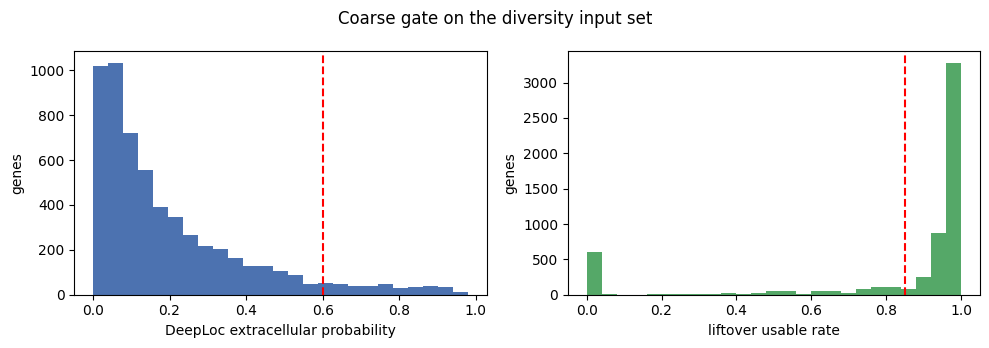

In [15]:
#@title Plot the gate
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

ax[0].hist(candidates.Extracellular.dropna(), bins=25, color='#4C72B0')
ax[0].axvline(EXTRACELLULAR_GATE, ls='--', c='r')
ax[0].set_xlabel('DeepLoc extracellular probability'); ax[0].set_ylabel('genes')

ax[1].hist(candidates.usable_rate.dropna(), bins=25, color='#55A868')
ax[1].axvline(USABLE_RATE_GATE, ls='--', c='r')
ax[1].set_xlabel('liftover usable rate'); ax[1].set_ylabel('genes')

fig.suptitle('Coarse gate on the diversity input set')
plt.tight_layout(); plt.show()

In [16]:
cols = ['gene_id', 'Protein_ID', 'Transcript_ID', 'Localizations',
        'Extracellular', 'usable_rate']
cols = [c for c in cols if c in diversity_input.columns]
diversity_input[cols].to_csv(PROJECT / '04_diversity_input.tsv', sep='\t', index=False)

# gffread matches the feature ID in the GFF, which carries the 'rna-' prefix
with open(IDS_FILE, 'w') as f:
    for tx in diversity_input.Transcript_ID.dropna().unique():
        f.write(f'rna-{tx}\n')

print(f'{len(diversity_input)} genes written to {IDS_FILE}')
!head -3 {IDS_FILE}

268 genes written to /content/candidate_transcript_ids.txt
rna-XM_026333911.1
rna-XM_026333920.1
rna-XM_026333964.1


---

## **2. Extract the CDS from every assembly.**

`gffread` reads a lifted GFF and its matching genome FASTA. It writes the nucleotide CDS (`-x`) and the translated protein (`-y`) for the requested transcripts only.

Two flags matter here:
- `-V` discards transcripts with in-frame stop codons or bad CDS phase;
- `-J` keeps only transcripts with a valid start and stop codon.

Both flags are strict on purpose. A truncated gene model from a fragmented assembly creates a frameshifted alignment, and a frameshifted alignment inflates πN.


In [17]:
# copy the lifted annotations into the project folder, and unpack the genomes
! mkdir -p {GFF_DIR}
! cp -n {LIFTOFF}/*.gff {GFF_DIR}/
! test -d {GEN_DIR} || unzip -q {GENOMES_ZIP} -d /content/ccay_genomes

print(len(list(GFF_DIR.glob('*.gff'))), 'lifted annotations')
print(len(list(GEN_DIR.glob('*'))), 'genome folders')

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
43 lifted annotations
45 genome folders


In [18]:
ok, failed = [], []

for gff in tqdm(sorted(GFF_DIR.glob('*.gff'))):
    acc = gff.stem

    hits = list((GEN_DIR / acc).glob('*_genomic.fna'))
    if len(hits) != 1:
        failed.append((acc, f'{len(hits)} genomic.fna found'))
        continue
    fna = hits[0]

    cds = CDS_DIR / f'{acc}.cds.fna'
    pep = CDS_DIR / f'{acc}.pep.faa'
    if cds.exists() and pep.exists():     # resume a previous run
        ok.append(acc)
        continue

    r = subprocess.run(
        ['gffread', '-V', '-J', str(gff), '-g', str(fna),
         '--ids', str(IDS_FILE), '-x', str(cds), '-y', str(pep)],
        capture_output=True, text=True,
    )
    if r.returncode != 0:
        failed.append((acc, r.stderr.strip()[:200]))
    else:
        ok.append(acc)

print(f'{len(ok)} ok, {len(failed)} failed')
for a, e in failed:
    print(' ', a, '|', e)

  0%|          | 0/43 [00:00<?, ?it/s]

37 ok, 6 failed
  GCA_059928115.1 | 0 genomic.fna found
  GCA_059928165.1 | 0 genomic.fna found
  GCA_059928195.1 | 0 genomic.fna found
  GCA_059928215.1 | 0 genomic.fna found
  GCA_059928235.1 | 0 genomic.fna found
  GCA_059928285.1 | 0 genomic.fna found


---

## **3. Group the sequences by gene.**

The output above is one file per assembly. SNPGenie needs the opposite: one file per gene, with one sequence from each assembly. This step inverts the layout and removes bad sequences at the same time.

| Drop reason | What it means | Why it is removed |
| :-- | :-- | :-- |
| `no cds` | the protein exists, the nucleotide CDS does not | pal2nal needs both |
| `empty` | zero-length translation | nothing to align |
| `internal stop` | a `*` or `.` inside the protein | the gene model is broken in this assembly |
| `len N vs pep M` | CDS length is not 3x the protein length | frameshift or partial model |
| `untranslatable` | Biopython cannot translate the CDS | bad characters, often a run of `N` |
| `translation mismatch` | the CDS does not translate to the protein | the GFF and the FASTA disagree |

Every drop is written to `04_dropped_sequences.csv`. Read it. A reason that is concentrated in one assembly points to a bad assembly. A reason that is concentrated in one gene points to a bad gene model.


In [19]:
pep_by_tx = defaultdict(dict)
cds_by_tx = defaultdict(dict)

for pep_f in sorted(CDS_DIR.glob('*.pep.faa')):
    acc = pep_f.name.replace('.pep.faa', '')
    cds_f = CDS_DIR / f'{acc}.cds.fna'
    if not cds_f.exists() or pep_f.stat().st_size == 0:
        print(f'skipping {acc}: missing or empty')
        continue
    for r in SeqIO.parse(pep_f, 'fasta'):
        pep_by_tx[r.id][acc] = r
    for r in SeqIO.parse(cds_f, 'fasta'):
        cds_by_tx[r.id][acc] = r

n_genomes = len({a for d in pep_by_tx.values() for a in d})
print(f'{len(pep_by_tx)} transcripts across {n_genomes} genomes')

63 transcripts across 37 genomes


In [20]:
dropped = defaultdict(list)   # transcript -> [(accession, reason)]
counts  = {}

for tx, per_acc in tqdm(pep_by_tx.items()):
    slug = tx.replace('|', '_').replace('/', '_')
    d = GENE_DIR / slug
    peps, cdss = [], []

    for acc, prec in sorted(per_acc.items()):
        crec = cds_by_tx.get(tx, {}).get(acc)
        if crec is None:
            dropped[tx].append((acc, 'no cds')); continue

        seq = str(prec.seq).rstrip('*.')
        if len(seq) == 0:
            dropped[tx].append((acc, 'empty')); continue
        if '*' in seq or '.' in seq:
            dropped[tx].append((acc, 'internal stop')); continue

        nt = str(crec.seq).rstrip()
        if len(nt) not in (len(seq) * 3, len(seq) * 3 + 3):
            dropped[tx].append((acc, f'len {len(nt)} vs pep {len(seq)}')); continue

        try:
            tr = str(Seq(nt[:len(seq) * 3]).translate()).rstrip('*')
        except Exception:
            dropped[tx].append((acc, 'untranslatable')); continue
        if tr != seq:
            dropped[tx].append((acc, 'translation mismatch')); continue

        prec = prec[:]; crec = crec[:]
        prec.id = prec.name = prec.description = acc
        crec.id = crec.name = crec.description = acc
        prec.seq = Seq(seq)
        crec.seq = Seq(nt[:len(seq) * 3])      # trim the trailing stop codon
        peps.append(prec); cdss.append(crec)

    counts[tx] = len(peps)
    if len(peps) < MIN_SEQS:
        continue
    d.mkdir(exist_ok=True)
    SeqIO.write(peps, d / 'pep.faa', 'fasta')
    SeqIO.write(cdss, d / 'cds.fna', 'fasta')

n_in = pd.Series(counts).rename('n_seqs')
print(n_in.describe())
print(f'genes with fewer than {MIN_SEQS} usable sequences:', (n_in < MIN_SEQS).sum())

  0%|          | 0/63 [00:00<?, ?it/s]

count    63.000000
mean     35.730159
std       0.901725
min      32.000000
25%      35.000000
50%      36.000000
75%      36.000000
max      37.000000
Name: n_seqs, dtype: float64
genes with fewer than 2 usable sequences: 0


In [21]:
drop_df = pd.DataFrame(
    [(tx, acc, why) for tx, lst in dropped.items() for acc, why in lst],
    columns=['tx', 'accession', 'reason'],
)
drop_df.to_csv(PROJECT / '04_dropped_sequences.csv', index=False)

if len(drop_df):
    # collapse the variable 'len X vs pep Y' messages into one label
    drop_df['reason_class'] = drop_df.reason.str.replace(r'^len \d+ vs pep \d+$',
                                                        'length mismatch', regex=True)
    print('total dropped:', len(drop_df), '\n')
    print(drop_df.reason_class.value_counts(), '\n')
    print('worst genomes:'); print(drop_df.accession.value_counts().head(10), '\n')
    print('worst genes:');   print(drop_df.tx.value_counts().head(10))

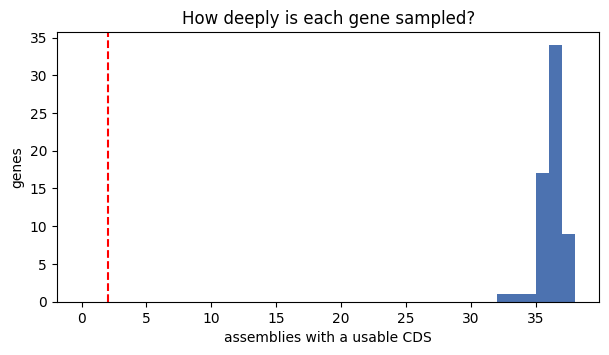

In [22]:
#@title Sequence depth per gene
plt.figure(figsize=(7, 3.5))
plt.hist(n_in.values, bins=range(0, int(n_in.max()) + 2), color='#4C72B0')
plt.axvline(MIN_SEQS, ls='--', c='r')
plt.xlabel('assemblies with a usable CDS'); plt.ylabel('genes')
plt.title('How deeply is each gene sampled?')
plt.show()

---

## **4. Align the codons.**

Align the proteins first, then push the nucleotides through that alignment. Do not align the nucleotides directly. A direct nucleotide alignment can open a gap that is not a multiple of three, which breaks the reading frame and makes the synonymous and nonsynonymous counts meaningless.

- **MAFFT** aligns the proteins. `--auto` picks the strategy from the number and length of the sequences.
- **pal2nal** maps that protein alignment back onto the CDS. `-nogap` removes any column with a gap, so every remaining column is a complete codon in every sequence.

`-nogap` is strict. It costs alignment length in genes with indels. It is the correct trade for this project, because SNPGenie requires an alignment length that divides by three.


In [23]:
aln_n = {}

for d in tqdm(sorted(GENE_DIR.iterdir())):
    pep, cds = d / 'pep.faa', d / 'cds.fna'
    if not pep.exists():
        continue
    aln, codon = d / 'pep.aln', d / 'codon.aln'

    # 1. align the protein sequences
    if not aln.exists() or aln.stat().st_size == 0:
        with open(aln, 'w') as fh:
            subprocess.run(['mafft', '--auto', '--quiet', '--thread', str(N_PROCS), str(pep)],
                           stdout=fh, check=True)

    # 2. convert to a codon alignment
    with open(codon, 'w') as fh:
        r = subprocess.run(['pal2nal', str(aln), str(cds), '-output', 'fasta', '-nogap'],
                           stdout=fh, stderr=subprocess.PIPE, text=True)

    if r.returncode != 0 or codon.stat().st_size == 0:
        aln_n[d.name] = 0
        print(f'{d.name}: pal2nal failed | {r.stderr.strip()[:150]}')
    else:
        aln_n[d.name] = sum(1 for l in open(codon) if l.startswith('>'))

  0%|          | 0/63 [00:00<?, ?it/s]

In [24]:
res = pd.DataFrame({'n_in': n_in, 'n_aligned': pd.Series(aln_n)}).fillna(0).astype(int)
res['lost_pal2nal'] = res.n_in - res.n_aligned
res.to_csv(PROJECT / '04_alignment_counts.csv')

print(res.sort_values('lost_pal2nal', ascending=False).head(10))
print(f'\n{(res.n_aligned >= MIN_SEQS).sum()} genes have a usable codon alignment')

                    n_in  n_aligned  lost_pal2nal
rna-XM_022730665.1    36         36             0
rna-XM_022731842.2    37         37             0
rna-XM_022731922.2    36         36             0
rna-XM_022732228.1    36         36             0
rna-XM_022734555.2    35         35             0
rna-XM_022734702.1    36         36             0
rna-XM_022737289.2    35         35             0
rna-XM_022737300.2    36         36             0
rna-XM_022737383.2    36         36             0
rna-XM_026334276.1    37         37             0

63 genes have a usable codon alignment


---

## **5. Measure diversity with SNPGenie.**

`snpgenie_within_group.pl` takes an aligned FASTA plus a GTF that says where the coding region is. It then applies the Nei and Gojobori (1986) method to every pairwise comparison in the group:

- **πN** — mean nonsynonymous differences per nonsynonymous site. This is the number we care about. It measures how much the **protein** changes between isolates.
- **πS** — mean synonymous differences per synonymous site. This is the local mutation rate, and it acts as the baseline.
- **πN/πS** — πN scaled by that baseline. Below 1 means purifying selection; the protein is held in place.

The alignment is one gene, so the GTF is one line: the whole alignment is the CDS, on the plus strand, in frame 0.

The loop below resumes. It reads an existing `within_group_codon_results.txt` instead of running the gene again. SNPGenie with 1000 bootstraps is the slowest step in the project, and Colab disconnects.


In [25]:
#@title Check what has already finished
completed, incomplete = [], []
for tx_dir in sorted(SNP_DIR.iterdir()):
    if not tx_dir.is_dir():
        continue
    summary = tx_dir / 'within_group_codon_results.txt'
    if summary.exists() and summary.stat().st_size > 0:
        completed.append(tx_dir.name)
    else:
        incomplete.append(tx_dir.name)

print(f'completed : {len(completed)}')
print(f'incomplete: {len(incomplete)}')
if incomplete:
    print('  ', ', '.join(incomplete[:20]))

completed : 63
incomplete: 0


In [26]:
SG = '/content/SNPGenie/snpgenie_within_group.pl'

results, failed = {}, []

for d in tqdm(sorted(GENE_DIR.iterdir())):
    codon = d / 'codon.aln'
    if not codon.exists() or not codon.stat().st_size:
        continue
    tx = d.name

    wd = SNP_DIR / tx
    summary = wd / 'within_group_codon_results.txt'

    if summary.exists() and summary.stat().st_size > 0:      # resume
        results[tx] = pd.read_csv(summary, sep='\t')
        continue

    recs = list(SeqIO.parse(codon, 'fasta'))
    if len(recs) < MIN_SEQS:
        continue
    L_nt = len(recs[0].seq)
    if L_nt % 3:
        failed.append((tx, f'alignment length {L_nt} is not divisible by 3')); continue

    if wd.exists():
        shutil.rmtree(wd)
    wd.mkdir(parents=True)

    shutil.copy(codon, wd / 'aln.fasta')
    (wd / 'ref.gtf').write_text(
        f'{recs[0].id}\tCCB\tCDS\t1\t{L_nt}\t.\t+\t0\tgene_id "{tx}";\n'
    )

    r = subprocess.run(
        ['perl', SG, '--fasta_file_name=aln.fasta', '--gtf_file_name=ref.gtf',
         f'--num_bootstraps={N_BOOTSTRAPS}', f'--procs_per_node={N_PROCS}'],
        cwd=wd, capture_output=True, text=True,
    )

    if not summary.exists() or summary.stat().st_size == 0:
        failed.append((tx, r.stderr.strip()[:200] or r.stdout.strip()[-200:]))
        continue
    results[tx] = pd.read_csv(summary, sep='\t')

print(f'{len(results)} ok, {len(failed)} failed')
for t, e in failed[:10]:
    print(' ', t, '|', e)

  0%|          | 0/63 [00:00<?, ?it/s]

63 ok, 0 failed


---

## **6. Collate the results.**

SNPGenie reports per codon. Sum the sites and the differences over the whole gene, then take the ratio once. Do not average the per-codon ratios, because codons with zero synonymous sites would divide by zero.

### **The πS = 0 problem**

Some genes have no synonymous variation at all across the 44 assemblies. Their πN/πS is undefined, and a filter like `piN_piS < 1` drops them without a word. That is the wrong result, because those genes are the **most** conserved genes in the set, which is exactly what a diagnostic target needs.

So classify each gene instead of relying on the ratio alone:

| `diversity_class` | Condition | Meaning |
| :-- | :-- | :-- |
| `invariant` | no N and no S differences | identical in every assembly; the best case |
| `synonymous_only` | πN = 0, πS > 0 | the protein is identical, the DNA is not; also excellent |
| `no_synonymous` | πN > 0, πS = 0 | the ratio is undefined; judge on πN alone |
| `ratio` | πN > 0, πS > 0 | πN/πS is meaningful |

Carry `piN` through to CCB05. It works for every class, and for binder design it is the more direct measurement: it is the amino-acid change the binder would see.


In [27]:
rows = []
for tx, df in results.items():
    rows.append({
        'transcript_raw': tx,
        'N_sites': df['N_sites'].sum(),
        'S_sites': df['S_sites'].sum(),
        'N_diffs': df['N_diffs'].sum(),
        'S_diffs': df['S_diffs'].sum(),
    })

cons = pd.DataFrame(rows)
cons['Transcript_ID'] = cons.transcript_raw.str.replace('^rna-', '', regex=True)

cons['piN'] = cons.N_diffs / cons.N_sites.replace(0, np.nan)
cons['piS'] = cons.S_diffs / cons.S_sites.replace(0, np.nan)
cons['piN_piS'] = cons.piN / cons.piS.replace(0, np.nan)

def classify(r):
    if r.N_diffs == 0 and r.S_diffs == 0:
        return 'invariant'
    if r.N_diffs == 0:
        return 'synonymous_only'
    if r.S_diffs == 0:
        return 'no_synonymous'
    return 'ratio'

cons['diversity_class'] = cons.apply(classify, axis=1)

# how many sequences went into each estimate; a low count makes the estimate weak
cons['n_aligned'] = cons.transcript_raw.map(res.n_aligned)

print(cons.diversity_class.value_counts(), '\n')
print(cons[['piN', 'piS', 'piN_piS', 'n_aligned']].describe())

diversity_class
invariant          22
no_synonymous      17
ratio              15
synonymous_only     9
Name: count, dtype: int64 

             piN        piS    piN_piS  n_aligned
count  62.000000  62.000000  24.000000  63.000000
mean    0.000232   0.000809   0.292262  35.730159
std     0.000479   0.001825   0.354156   0.901725
min     0.000000   0.000000   0.000000  32.000000
25%     0.000000   0.000000   0.000000  35.000000
50%     0.000029   0.000000   0.148695  36.000000
75%     0.000213   0.000654   0.481377  36.000000
max     0.002499   0.009091   1.260609  37.000000


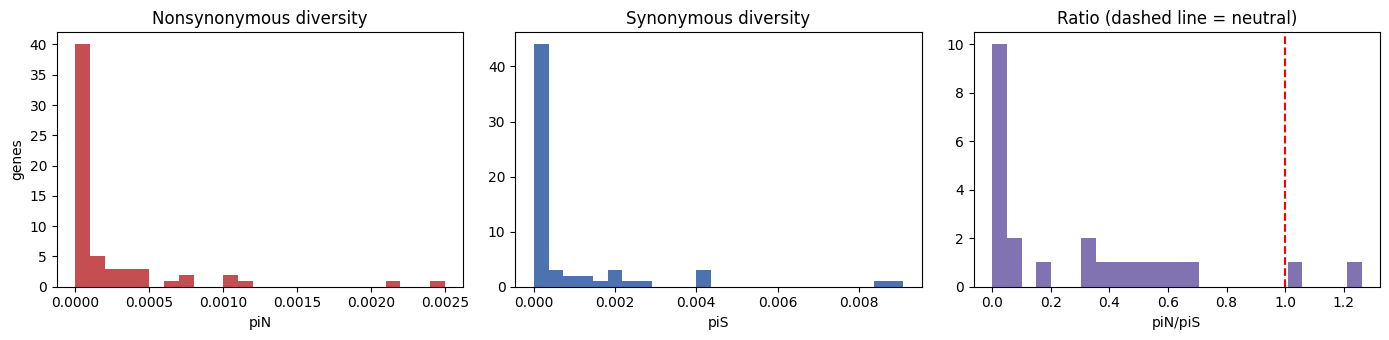

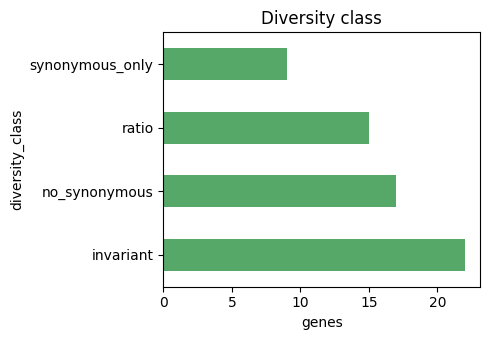

In [28]:
#@title Diversity distributions
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))

ax[0].hist(cons.piN.dropna(), bins=25, color='#C44E52')
ax[0].set_xlabel('piN'); ax[0].set_ylabel('genes'); ax[0].set_title('Nonsynonymous diversity')

ax[1].hist(cons.piS.dropna(), bins=25, color='#4C72B0')
ax[1].set_xlabel('piS'); ax[1].set_title('Synonymous diversity')

ax[2].hist(cons.piN_piS.dropna(), bins=25, color='#8172B2')
ax[2].axvline(1.0, ls='--', c='r')
ax[2].set_xlabel('piN/piS'); ax[2].set_title('Ratio (dashed line = neutral)')

plt.tight_layout(); plt.show()

plt.figure(figsize=(5, 3.5))
cons.diversity_class.value_counts().plot(kind='barh', color='#55A868')
plt.xlabel('genes'); plt.title('Diversity class'); plt.tight_layout(); plt.show()

In [29]:
out_cols = ['Transcript_ID', 'transcript_raw', 'n_aligned',
            'N_sites', 'S_sites', 'N_diffs', 'S_diffs',
            'piN', 'piS', 'piN_piS', 'diversity_class']
cons[out_cols].to_csv(PROJECT / '04_diversity.csv', index=False)

print(f'{len(cons)} genes written to {PROJECT / "04_diversity.csv"}')
cons.sort_values('piN').head(15)

63 genes written to /content/drive/MyDrive/CCayProject/04_diversity.csv


,transcript_raw,N_sites,S_sites,N_diffs,S_diffs,Transcript_ID,piN,piS,piN_piS,diversity_class,n_aligned
0,rna-XM_022730665.1,1410.500000,404.500000,0.0,0.268254,XM_022730665.1,0.0,0.000663,0.0,synonymous_only,36
2,rna-XM_022731922.2,956.000000,295.000000,0.0,0.000000,XM_022731922.2,0.0,0.000000,NaN,invariant,36
3,rna-XM_022732228.1,960.000000,288.000000,0.0,0.000000,XM_022732228.1,0.0,0.000000,NaN,invariant,36
4,rna-XM_022734555.2,1575.333333,458.666667,0.0,0.000000,XM_022734555.2,0.0,0.000000,NaN,invariant,35
5,rna-XM_022734702.1,263.500000,78.500000,0.0,0.000000,XM_022734702.1,0.0,0.000000,NaN,invariant,36
10,rna-XM_026334299.1,1999.000000,641.000000,0.0,0.000000,XM_026334299.1,0.0,0.000000,NaN,invariant,37
13,rna-XM_026334540.1,1655.000000,517.000000,0.0,0.000000,XM_026334540.1,0.0,0.000000,NaN,invariant,36
32,rna-XM_026336286.1,547.833333,184.166667,0.0,0.000000,XM_026336286.1,0.0,0.000000,NaN,invariant,36
26,rna-XM_026335435.1,1344.333333,386.666667,0.0,0.000000,XM_026335435.1,0.0,0.000000,NaN,invariant,36
27,rna-XM_026335655.1,1707.500000,539.500000,0.0,0.000000,XM_026335655.1,0.0,0.000000,NaN,invariant,34


---

### **Next**

`04_diversity.csv` goes into **CCB05**, where it is joined to the abundance estimates and the localization predictions. CCB05 applies the strict thresholds and takes the intersection.

**Before you continue, check these:**
1. `04_dropped_sequences.csv` — is one assembly responsible for most of the drops? If yes, remove it and re-run, because it is adding noise to every gene.
2. `n_aligned` — a gene measured on 8 assemblies is far weaker evidence than one measured on 42. Set a minimum in CCB05.
3. The `no_synonymous` genes — their πN/πS is missing, not bad. Handle them explicitly.
